# Parameter-Efficient Fine-tuning

In this workshop, we will attempt to fine-tune the GPT2-small model for the task of sentiment analysis using various PEFT methods:
1. LoRa – Low-Rank Adaptation
1. Prompt tuning
1. PEFT + LP-FT

## Dataset

To evaluate the quality of fine-tuning, we will use one of the GLUE benchmark datasets, [SST2](https://huggingface.co/datasets/sst2) (Stanford Sentiment Treebank). The dataset contains 67,000 sentences with movie reviews that need to be classified as positive or negative.

In [1]:
import torch
from torch import nn
import subprocess
import os

os.environ['TOKENIZERS_PARALLELISM'] = 'false'

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [2]:
from datasets import load_dataset

train_dataset = load_dataset("glue", "sst2", split='train[:50000]')
valid_dataset = load_dataset("glue", "sst2", split="validation")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

sst2/train-00000-of-00001.parquet:   0%|          | 0.00/3.11M [00:00<?, ?B/s]

sst2/validation-00000-of-00001.parquet:   0%|          | 0.00/72.8k [00:00<?, ?B/s]

sst2/test-00000-of-00001.parquet:   0%|          | 0.00/148k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

In [3]:
train_dataset[0]

{'sentence': 'hide new secretions from the parental units ',
 'label': 0,
 'idx': 0}

In [4]:
train_dataset[2]

{'sentence': 'that loves its characters and communicates something rather beautiful about human nature ',
 'label': 1,
 'idx': 2}

In [5]:
len(train_dataset), len(valid_dataset)

(50000, 872)

### Initializing the tokenizer and model

In [7]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

In [8]:
model_checkpoint = "gpt2"

In [9]:
# Initializing the tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
tokenizer.add_special_tokens({'pad_token': '[PAD]'})

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

1

In [10]:
class Model(nn.Module):
    def __init__(self, tokenizer, num_classes=2):
        super().__init__()
        self.model = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, num_labels=num_classes)
        self.model.resize_token_embeddings(len(tokenizer))
        self.config = self.model.config

    def forward(self, input_ids=None, attention_mask=None, inputs_embeds=None, *args, **kwargs):
        out = self.model.transformer(
            input_ids=input_ids, inputs_embeds=inputs_embeds, attention_mask=attention_mask
        ).last_hidden_state
        lens = attention_mask.sum(-1).cpu() - 1
        out = out[torch.arange(len(lens)), lens.to(torch.long)]
        return self.model.score(out)

    @property
    def device(self):
        return next(self.model.parameters()).device


num_classes = 2
model = Model(tokenizer, num_classes)

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


In [11]:
model

Model(
  (model): GPT2ForSequenceClassification(
    (transformer): GPT2Model(
      (wte): Embedding(50258, 768)
      (wpe): Embedding(1024, 768)
      (drop): Dropout(p=0.1, inplace=False)
      (h): ModuleList(
        (0-11): 12 x GPT2Block(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (attn): GPT2Attention(
            (c_attn): Conv1D(nf=2304, nx=768)
            (c_proj): Conv1D(nf=768, nx=768)
            (attn_dropout): Dropout(p=0.1, inplace=False)
            (resid_dropout): Dropout(p=0.1, inplace=False)
          )
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): GPT2MLP(
            (c_fc): Conv1D(nf=3072, nx=768)
            (c_proj): Conv1D(nf=768, nx=3072)
            (act): NewGELUActivation()
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
      )
      (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    )
    (score): Linear(in_features=768, out_fea

In [12]:
sum(p.numel() for p in model.parameters())

124442112

### Tokenizer healthcheck

In [13]:
# Running tokenizer on sample data
tokenizer(train_dataset[0]["sentence"])

{'input_ids': [24717, 649, 3200, 507, 422, 262, 21694, 4991, 220], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [14]:
from torch.utils.data import DataLoader

In [15]:
batch_size = 128

train_loader = DataLoader(train_dataset, shuffle=True, batch_size=batch_size, num_workers=8)
valid_loader = DataLoader(valid_dataset, shuffle=False, batch_size=batch_size, num_workers=8)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [16]:
import numpy as np

# Percentage of classes in dataset

print("       0       1")
classes = [t["label"] for t in train_dataset]
print(f"Train: {1 - np.mean(classes):0.3f} {np.mean(classes):0.3f}")

classes = [t["label"] for t in valid_dataset]
print(f"Valid: {1 - np.mean(classes):0.3f} {np.mean(classes):0.3f}")

       0       1
Train: 0.442 0.558
Valid: 0.491 0.509


### Function implementation for model training

In [18]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 32.6 MB/s eta 0:00:00


In [19]:
from IPython.display import clear_output
from random import sample
from tqdm import tqdm
import matplotlib.pyplot as plt
from torchmetrics.functional import accuracy
from torch.optim import AdamW
import seaborn as sns

sns.set_theme()

In [20]:
_ = model.to(device)

In [21]:
def training_loop_fn(model, opt, total_num_iters, eval_freq, train_loader, valid_loader):
    train_loss_history, eval_loss_history = [], []
    train_acc_history, eval_acc_history = [], []
    global_step = 0

    criterion = torch.nn.CrossEntropyLoss()
    model.train()
    while True:
        for batch in tqdm(train_loader):
            tokenized = tokenizer(batch["sentence"], padding=True, return_tensors='pt')
            for k, v in tokenized.items():
                tokenized[k] = v.to(device)

            with torch.autocast(device_type='cuda', dtype=torch.float16):
                logits = model(tokenized['input_ids'], tokenized['attention_mask'], return_dict=False)
            targets = batch["label"].to(device)
            loss = criterion(logits, targets)

            opt.zero_grad()
            loss.backward()
            opt.step()

            preds = torch.nn.functional.softmax(logits, dim=-1)[:, 1]
            acc = accuracy(preds, targets, "binary")

            train_loss_history.append((global_step, loss.item()))
            train_acc_history.append((global_step, acc.item()))

            if global_step % eval_freq == 0:
                val_loss, val_acc = evaluate(model, valid_loader)
                eval_loss_history.append((global_step, val_loss))
                eval_acc_history.append((global_step, val_acc))

                model.train()

            if global_step % 250 == 0:
                clear_output(True)

                plt.figure(figsize=(15, 5))

                plt.subplot(121)
                plt.plot(*zip(*train_loss_history), alpha=0.5, label='train_loss')
                if len(eval_loss_history):
                    plt.plot(*zip(*eval_loss_history), color='red', label='eval_loss')
                plt.legend()

                plt.subplot(122)
                plt.plot(*zip(*train_acc_history), alpha=0.5, label='train_acc')
                if len(eval_acc_history):
                    plt.plot(*zip(*eval_acc_history), color='red', label='eval_acc')
                plt.legend()
                plt.show()

            global_step += 1
            if global_step > total_num_iters:
                break
        else:
            continue
        break


@torch.no_grad()
def evaluate(model, dataloader):
    model.eval()
    criterion = torch.nn.CrossEntropyLoss()
    loss_epoch = 0.
    num_epoch = 0.
    preds_list = []
    targets_list = []

    for eval_batch in dataloader:
        tokenized = tokenizer(eval_batch["sentence"], padding=True, return_tensors='pt')
        for k, v in tokenized.items():
            tokenized[k] = v.to(device)

        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits = model(tokenized['input_ids'], tokenized['attention_mask'], return_dict=False)

        loss = criterion(logits, eval_batch["label"].to(device))
        num = logits.shape[0]

        loss_epoch += loss.item() * num
        num_epoch += num
        preds = torch.nn.functional.softmax(logits, dim=-1)[:, 1]

        targets_list += eval_batch["label"].tolist()
        preds_list += preds.tolist()

    acc = accuracy(torch.tensor(preds_list).to(device), torch.tensor(targets_list).to(device), "binary")

    return loss_epoch / num_epoch, acc.item()

## Fine-tuning

We train all model weights. This approach will be the most memory-intensive, but it is the most commonly used.

In [22]:
model = Model(tokenizer, num_classes).to(device)
optimizer = AdamW(model.parameters(), lr=2e-6)

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


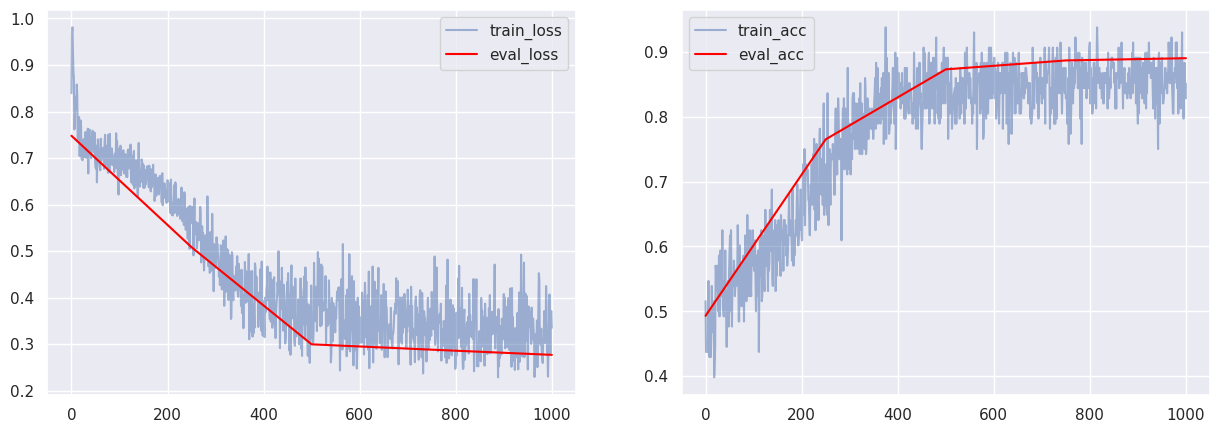

 56%|█████▌    | 218/391 [01:35<01:15,  2.28it/s]

CPU times: user 6min 18s, sys: 4.96 s, total: 6min 23s
Wall time: 7min 28s


In [23]:
%%time
training_loop_fn(model, optimizer, 1000, 250, train_loader, valid_loader)

In [24]:
val_loss, val_acc = evaluate(model, valid_loader)
print(f'val loss: {val_loss}')
print(f'val accuracy: {val_acc}')

val loss: 0.2772407181766055
val accuracy: 0.8899082541465759


## Linear Probing

We tune only the last linear layer (so-called head) of the model.

In [25]:
del model

In [26]:
torch.cuda.empty_cache()

In [27]:
model = Model(tokenizer, num_classes).to(device)
optimizer = AdamW(model.model.score.parameters(), lr=1e-4)

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


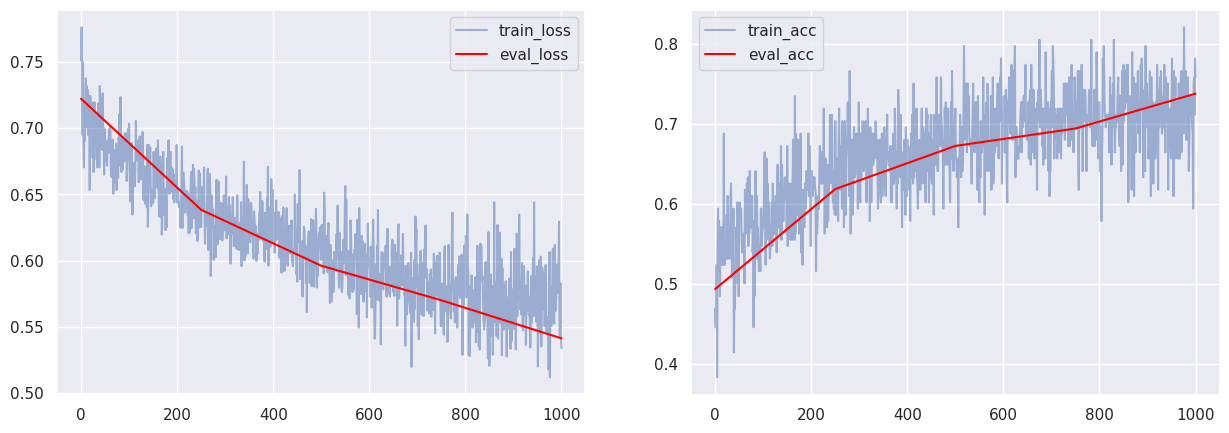

 56%|█████▌    | 218/391 [01:26<01:08,  2.51it/s]

CPU times: user 6min 23s, sys: 3.74 s, total: 6min 27s
Wall time: 6min 34s


In [28]:
%%time
training_loop_fn(model, optimizer, 1000, 250, train_loader, valid_loader)

In [29]:
val_loss, val_acc = evaluate(model, valid_loader)
print(f'val loss: {val_loss}')
print(f'val accuracy: {val_acc}')

val loss: 0.5411948107798165
val accuracy: 0.7373853325843811


In [30]:
torch.save(model.model.score.state_dict(), "head.pt")

## LoRa

In the original article, the authors suggest training only the $W_K$ and $W_V$ matrices in the transformer's attention layers and the last linear layer. However, we will add the $W_Q$ matrix to them, because in the GPT architecture, all three matrices are calculated using a single layer, and separating them would be too inconvenient.

<img src="https://heidloff.net/assets/img/2023/08/lora.png" alt="drawing" width="600"/>

To implement Parameter-Efficient Fine-Tuning, we will use the `peft` library (`huggingface` family). It implements many of the most successful methods for retraining models. The full list can be found [here](https://github.com/huggingface/peft).

The most important parameter of this model is the rank of matrices $A$ and $B$ ($r$). Increasing it gives more degrees of freedom in adjusting the $AB$ additive, thereby increasing the number of trainable parameters.

In [31]:
model

Model(
  (model): GPT2ForSequenceClassification(
    (transformer): GPT2Model(
      (wte): Embedding(50258, 768)
      (wpe): Embedding(1024, 768)
      (drop): Dropout(p=0.1, inplace=False)
      (h): ModuleList(
        (0-11): 12 x GPT2Block(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (attn): GPT2Attention(
            (c_attn): Conv1D(nf=2304, nx=768)
            (c_proj): Conv1D(nf=768, nx=768)
            (attn_dropout): Dropout(p=0.1, inplace=False)
            (resid_dropout): Dropout(p=0.1, inplace=False)
          )
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): GPT2MLP(
            (c_fc): Conv1D(nf=3072, nx=768)
            (c_proj): Conv1D(nf=768, nx=3072)
            (act): NewGELUActivation()
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
      )
      (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    )
    (score): Linear(in_features=768, out_fea

In [32]:
from peft import get_peft_model, LoraConfig, TaskType

In [33]:
peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS, inference_mode=False, r=8, lora_dropout=0.1, target_modules=['c_attn']
)

model = Model(tokenizer, num_classes).to(device)
lora_model = get_peft_model(model, peft_config).to(device)
lora_model.print_trainable_parameters()

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 296,448 || all params: 124,738,560 || trainable%: 0.2377


/usr/local/lib/python3.12/dist-packages/peft/tuners/lora/layer.py:2285: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


In [34]:
sum(p.numel() for p in lora_model.parameters() if p.requires_grad)

296448

In [35]:
optimizer = AdamW(lora_model.parameters(), lr=1e-4)

In [36]:
torch.cuda.empty_cache()

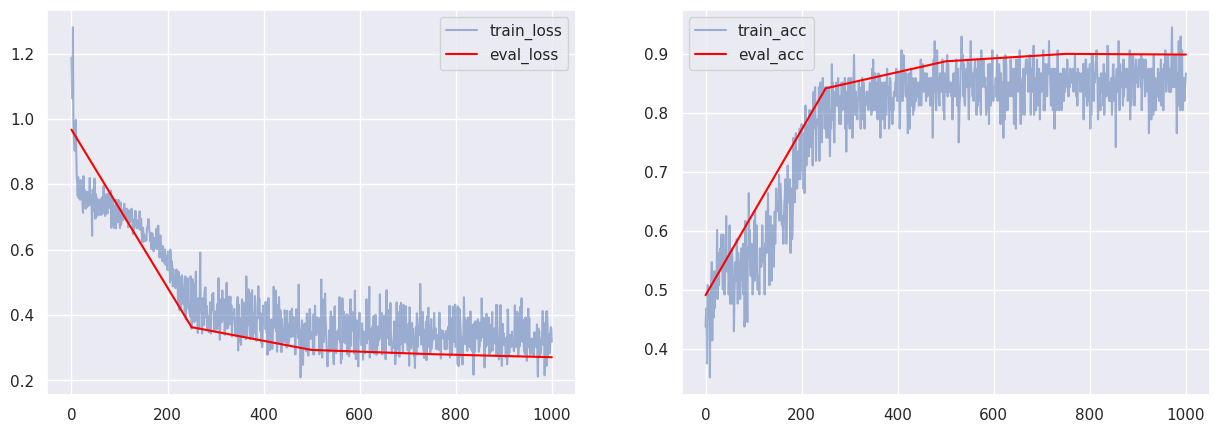

 56%|█████▌    | 218/391 [01:22<01:05,  2.65it/s]

CPU times: user 5min 57s, sys: 4.14 s, total: 6min 2s
Wall time: 6min 11s


In [37]:
%%time
training_loop_fn(lora_model, optimizer, 1000, 250, train_loader, valid_loader)

In [38]:
val_loss, val_acc = evaluate(lora_model, valid_loader)
print(f'val loss: {val_loss}')
print(f'val accuracy: {val_acc}')

val loss: 0.2707877902809633
val accuracy: 0.8990825414657593


In [39]:
torch.save(lora_model.base_model.model.model.score.state_dict(), 'lora_head.pt')

## Prompt Tuning

Prompt Tuning is the most architecture-dependent method of tuning of the models, as it is based on the observation that large language models are capable of solving tasks in a zero-shot and few-shot paradigm (i.e., relying only on the input prompt and the text for which a response is required; in zero shot there are no examples, but in a few-shot scenario there are few for the desired output style). For models that can work in this format, Prompt Tuning suggests not selecting the prompt manually, but training it. Thus, this method will work best with GPT-type models and worst with BERT. Along with the prompt, the head is additionally tuned.

<!-- <img src="attachment:60eae4f0-193d-4108-b9c2-8d37e54f791e.png" alt="drawing" width="800"/> -->
![image](attachment:60eae4f0-193d-4108-b9c2-8d37e54f791e.png)


When configuring the prompt, you can vary its length as well as the initialization method. The rule here is: the larger the dataset for fine-tuning, the longer the prompts can be. If the dataset is small, a long prompt will not be able to learn.

In [40]:
from peft import PromptTuningConfig, PromptTuningInit

In [41]:
len(tokenizer("Predict if sentiment of this review is positive or negative")['input_ids'])

11

In [42]:
init = {PromptTuningInit.TEXT: "Predict if sentiment of this review is positive or negative"}

In [43]:
config = model.config
peft_config = PromptTuningConfig(
    prompt_tuning_init=init,
    task_type=TaskType.SEQ_CLS,
    inference_mode=False,
    num_virtual_tokens=12,
    num_layers=config.n_layer,
    token_dim=config.n_embd,
    num_attention_heads=config.n_head,
)

model = Model(tokenizer, num_classes).to(device)
pt_model = get_peft_model(model, peft_config).to(device)
pt_model.print_trainable_parameters()

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 10,752 || all params: 124,452,864 || trainable%: 0.0086


In [44]:
del lora_model

In [45]:
torch.cuda.empty_cache()

In [46]:
optimizer = AdamW(pt_model.parameters(), lr=1e-4)

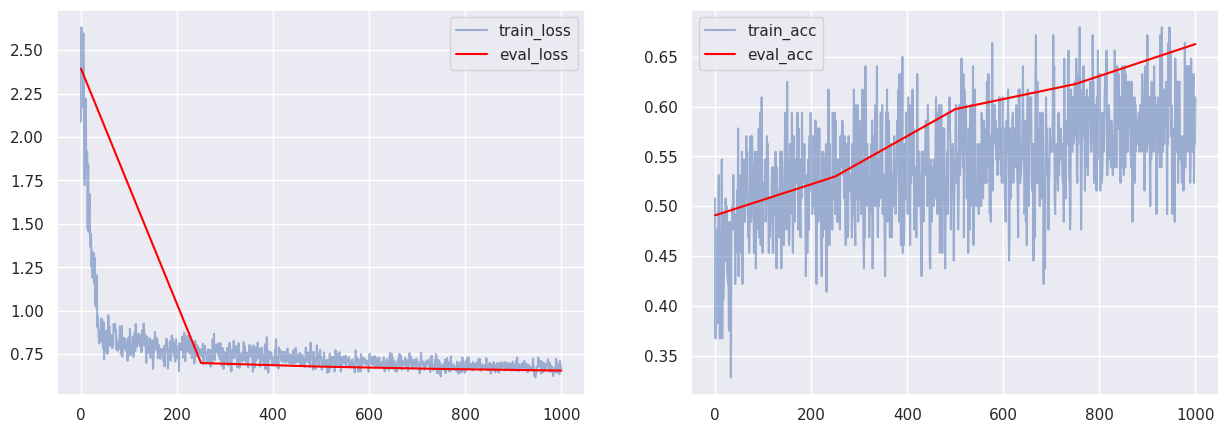

 56%|█████▌    | 218/391 [01:33<01:14,  2.32it/s]

CPU times: user 6min 56s, sys: 3.99 s, total: 7min
Wall time: 7min 8s


In [47]:
%%time
training_loop_fn(pt_model, optimizer, 1000, 250, train_loader, valid_loader)

In [48]:
val_loss, val_accuracy = evaluate(pt_model, valid_loader)
print(f'val loss: {val_loss}')
print(f'val acc: {val_accuracy}')

val loss: 0.6559857009747706
val acc: 0.6628440618515015


## LP-FT

In [49]:
chkpt = torch.load('head.pt')
chkpt.keys()

odict_keys(['weight'])

In [50]:
chkpt

OrderedDict([('weight',
              tensor([[-0.0249, -0.0078, -0.0303,  ...,  0.0072, -0.0337,  0.0059],
                      [-0.0403,  0.0068, -0.0147,  ..., -0.0221, -0.0062, -0.0794]],
                     device='cuda:0'))])

In [51]:
model = Model(tokenizer, num_classes).to(device)
model.model.score.load_state_dict(chkpt)
optimizer = AdamW(model.parameters(), lr=2e-6)

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


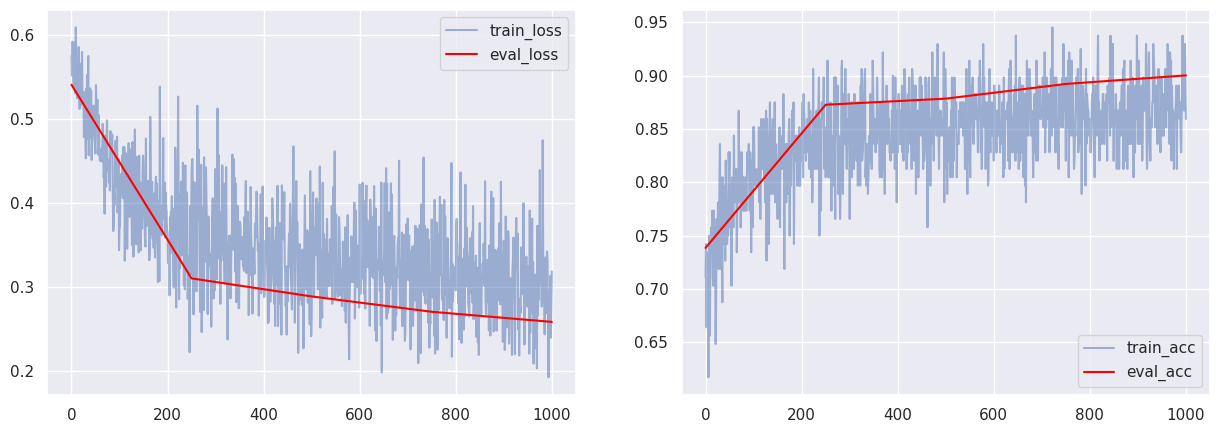

 56%|█████▌    | 218/391 [01:35<01:15,  2.28it/s]

CPU times: user 7min 2s, sys: 4.44 s, total: 7min 6s
Wall time: 7min 14s


In [52]:
%%time
training_loop_fn(model, optimizer, 1000, 250, train_loader, valid_loader)

In [53]:
val_loss, val_acc = evaluate(model, valid_loader)
print(f'val loss: {val_loss}')
print(f'val accuracy: {val_acc}')

val loss: 0.2580017649799312
val accuracy: 0.9002293348312378


### Testing the model

In [54]:
@torch.no_grad()
def predict(text, target=0):
    tokenized = tokenizer(text, return_tensors='pt')
    for k, v in tokenized.items():
        tokenized[k] = v.to(device)

    logits = model(tokenized['input_ids'], tokenized['attention_mask'], return_dict=False)
    probs = torch.nn.functional.softmax(logits, dim=-1)

    predicted_class_id = int(torch.argmax(logits, dim=-1))
    print(f"text: {text}")
    print(f"target: {target}, pred: {predicted_class_id}")
    print("probs:", probs.cpu().numpy())

In [55]:
predict("this movie is amaizing", 1)

text: this movie is amaizing
target: 1, pred: 1
probs: [[0.340635 0.659365]]


In [56]:
for i in range(10):
    text = valid_dataset[i]["sentence"]
    label = valid_dataset[i]["label"]
    predict(text, label)
    print()

text: it 's a charming and often affecting journey . 
target: 1, pred: 1
probs: [[0.00160705 0.9983929 ]]

text: unflinchingly bleak and desperate 
target: 0, pred: 0
probs: [[0.88659453 0.11340547]]

text: allows us to hope that nolan is poised to embark a major career as a commercial yet inventive filmmaker . 
target: 1, pred: 1
probs: [[0.02826312 0.97173685]]

text: the acting , costumes , music , cinematography and sound are all astounding given the production 's austere locales . 
target: 1, pred: 1
probs: [[0.01348071 0.9865193 ]]

text: it 's slow -- very , very slow . 
target: 0, pred: 0
probs: [[0.978437   0.02156304]]

text: although laced with humor and a few fanciful touches , the film is a refreshingly serious look at young women . 
target: 1, pred: 1
probs: [[0.01107101 0.988929  ]]

text: a sometimes tedious film . 
target: 0, pred: 0
probs: [[0.9650527 0.0349473]]

text: or doing last year 's taxes with your ex-wife . 
target: 0, pred: 0
probs: [[0.86342865 0.13657135]